# 02 · Phase 2: Reproducing Severson et al. (2019)

**Goal (RQ1).** Rebuild the paper's three cycle-life models on *our* cleaned data and check that
we get the paper's Table 1. If we do, then any later difference between models (Phase 3+) comes from
the models, not from our data handling.

**What Phase 2 does, end to end**

```
dataset.pkl (Phase 1, cleaned)  ──►  src/extras.py    per-cycle temperature integral from raw traces
                                ──►  src/features.py  20 features per cell, cycles ≤ 100 only  ──► features.csv
features.csv                    ──►  src/reproduce.py 3 models fitted on 41 train cells        ──► results/p2_reproduction.json
                                     src/evaluate.py  RMSE / % error, constant & policy baselines
```

**Prerequisite** (from the repo root, once):
```
python3 -m src.extras && python3 -m src.features && python3 -m src.reproduce
```
This notebook re-fits every model live (each fit takes ~1 s), so all the numbers you see are recomputed here.

| § | What you see |
|---|---|
| 1 | The prediction task and the split (41 / 43 / 40 cells) |
| 2 | The key signal: ΔQ(V) = Q₁₀₀(V) − Q₁₀(V) |
| 3 | The 20 candidate features, one cell computed **by hand** |
| 4 | Which features relate to life (training cells only) |
| 5 | The three models: variance (OLS), discharge and full (elastic net) |
| 6 | Results vs the paper's Table 1, parity plots |
| 7 | Where the errors come from |
| 8 | Case study: how the reproduction exposed a data fault in `b1c18` |
| 9 | Stability over cross-validation seeds |
| 10 | Explore any cell: features + predictions |
| 11 | Summary: answer to RQ1 |

Source tags used in the text: **[paper]** stated in Severson et al. or its SI, **[data]** measured here,
**[ours]** our implementation choice.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

from config import VDLIN, EOL_AH
from src.data import load_dataset, load_splits, curve
from src.features import FEATURE_SETS, ALL_CANDIDATES, load_features, delta_q, value_at
from src.evaluate import scores, constant_baseline, policy_baseline
from src.reproduce import make_model, subsets, fit_one, baselines, PAPER, PAPER_FULL_COEF

%matplotlib inline
mpl.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "legend.frameon": False, "font.size": 9})
C1, C2, C3, C4, INK2, BAD = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#52514e", "#d03b3b"
BLUES = LinearSegmentedColormap.from_list("blues", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#104281", "#0d366b"])
SPLIT_STYLE = {"train": ("train", C1, "o"), "primary_test": ("primary test", C2, "s"),
               "secondary_test": ("secondary test", C3, "^")}
pd.set_option("display.width", 160, "display.max_columns", 30)

ds, sp = load_dataset(), load_splits()
cells = ds["cells"]
df = load_features()                       # one row per cell, 20 features + labels
paper = df[df.split != "unseen"]           # the paper's 124 cells
train = df[df.split == "train"]
print(f"{len(df)} cells in features.csv; paper splits: "
      + ", ".join(f"{k} {v}" for k, v in paper.split.value_counts().items()))

163 cells in features.csv; paper splits: primary_test 43, train 41, secondary_test 40


## 1 · The task

* **Input:** only the first 100 cycles of each cell.
* **Output:** its **cycle life** = the first cycle where discharge capacity falls below 0.88 Ah (80% of 1.1 Ah) [paper].
* **Target used for fitting:** log₁₀(cycle life) [paper]. Lives span 148–2237 cycles (15×); on a log scale
  a 10% error counts the same for a short and a long cell.
* **Split** [paper, SI Table 9; reproduced exactly in Phase 1]:
  * **train** (41 cells) — used for fitting *and* choosing hyper-parameters,
  * **primary test** (43 cells) — same batches (b1, b2) as train, interleaved,
  * **secondary test** (40 cells) — batch b3, run ~1 year later with a different procedure.
* The **unseen** batch u1 is not used here (it is for RQ5 later).

Note that a test cell may share a charging policy with a training cell (primary), or not (secondary).

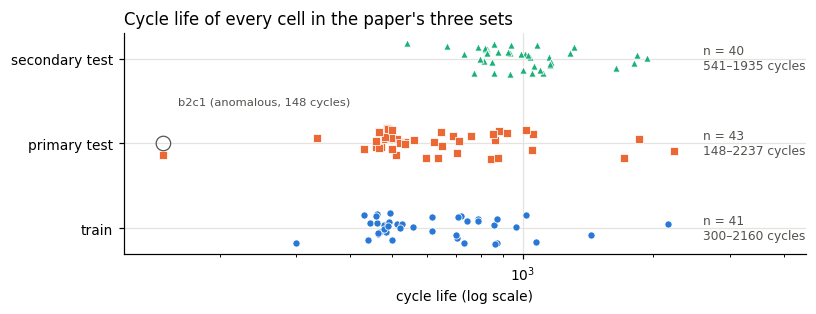

split,primary_test,secondary_test,train
batch,,,
b1,21,0,20
b2,22,0,21
b3,0,40,0


In [2]:
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (split, (lab, col, mk)) in enumerate(SPLIT_STYLE.items()):
    d = paper[paper.split == split]
    y = i + np.random.default_rng(0).uniform(-0.18, 0.18, len(d))
    ax.scatter(d.cycle_life, y, color=col, marker=mk, s=22, edgecolor="white", lw=0.5)
    ax.text(2600, i, f"n = {len(d)}\n{d.cycle_life.min():.0f}–{d.cycle_life.max():.0f} cycles",
            va="center", fontsize=8, color=INK2)
an = paper[paper.anomalous]
ax.scatter(an.cycle_life, [1] * len(an), s=90, facecolor="none", edgecolor=INK2, lw=0.8)
ax.annotate("b2c1 (anomalous, 148 cycles)", (an.cycle_life.iloc[0], 1), xytext=(160, 1.45), fontsize=7.5, color=INK2)
ax.set_yticks(range(3)); ax.set_yticklabels([v[0] for v in SPLIT_STYLE.values()])
ax.set_xscale("log"); ax.set_xlim(120, 4500); ax.set_xlabel("cycle life (log scale)")
ax.set_title("Cycle life of every cell in the paper's three sets", loc="left")
plt.show()

pd.crosstab(paper.batch, paper.split)

## 2 · The key signal: ΔQ(V)

`Qdlin` is the discharge capacity (Ah) as a function of voltage, interpolated by the authors on a
1000-point grid from 3.5 V down to 2.0 V, for the **4C constant-current part** of the discharge [paper; data].

The paper's main feature is the change in this curve between cycle 10 and cycle 100:

$$\Delta Q_{100-10}(V) = Q_{100}(V) - Q_{10}(V)$$

Why it works [paper]: early degradation (mainly loss of active material at the graphite electrode, *LAMdeNE*)
changes the **shape** of the voltage curve long before it changes the total capacity. ΔQ(V) picks up that
shape change; its variance across voltage summarises it in one number.

Below: a long-lived and a short-lived training cell.

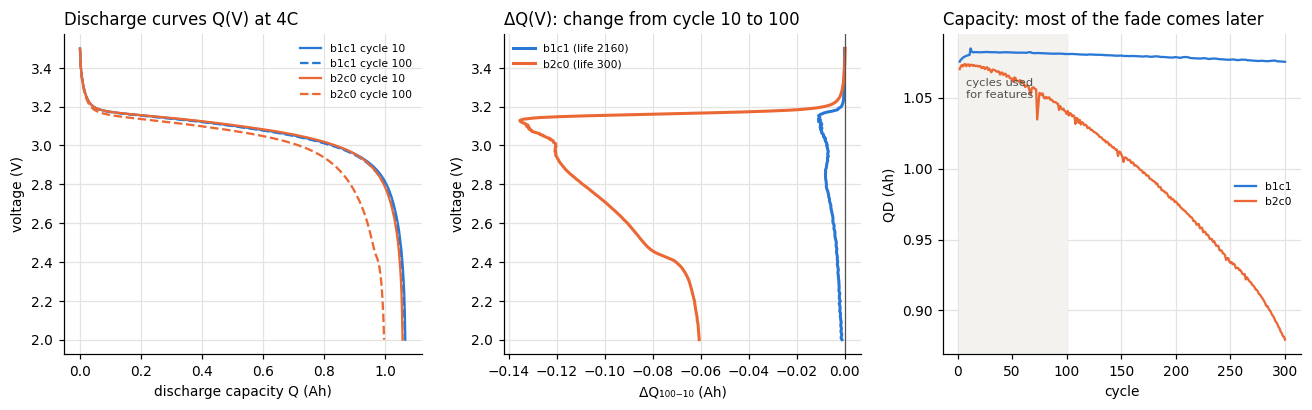

b1c1: life  2160 | QD(100)-QD(10) =   +0.9 mAh | min ΔQ =  -11.0 mAh | Var ΔQ = 9.69e-06 Ah² | log10 Var = -5.01
b2c0: life   300 | QD(100)-QD(10) =  -34.9 mAh | min ΔQ = -135.4 mAh | Var ΔQ = 1.80e-03 Ah² | log10 Var = -2.75


In [3]:
LONG, SHORT = "b1c1", "b2c0"          # 2160 and 300 cycles, both training cells
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for cid, col in [(LONG, C1), (SHORT, C2)]:
    c = cells[cid]
    q10, q100 = curve(c, "Qdlin", 10), curve(c, "Qdlin", 100)
    axes[0].plot(q10, VDLIN, color=col, lw=1.5, label=f"{cid} cycle 10")
    axes[0].plot(q100, VDLIN, color=col, lw=1.5, ls="--", label=f"{cid} cycle 100")
    axes[1].plot(q100 - q10, VDLIN, color=col, lw=2, label=f"{cid} (life {c['cycle_life']:.0f})")
    s = c["summary"]; m = (s["cycle"] >= 2) & (s["cycle"] <= 300)
    axes[2].plot(s["cycle"][m], s["QD_clean"][m], color=col, lw=1.5, label=cid)
axes[0].set(xlabel="discharge capacity Q (Ah)", ylabel="voltage (V)", title="Discharge curves Q(V) at 4C")
axes[0].legend(fontsize=7)
axes[1].axvline(0, color=INK2, lw=0.8)
axes[1].set(xlabel="ΔQ₁₀₀₋₁₀ (Ah)", ylabel="voltage (V)", title="ΔQ(V): change from cycle 10 to 100")
axes[1].legend(fontsize=7)
axes[2].axvspan(2, 100, color="#f3f2ee"); axes[2].text(8, 1.05, "cycles used\nfor features", fontsize=7.5, color=INK2)
axes[2].set(xlabel="cycle", ylabel="QD (Ah)", title="Capacity: most of the fade comes later")
axes[2].legend(fontsize=7)
for ax in axes: ax.title.set_ha("left"); ax.title.set_position((0, 1))
plt.tight_layout(); plt.show()

for cid in (LONG, SHORT):
    c = cells[cid]; dq = delta_q(c)
    print(f"{cid}: life {c['cycle_life']:5.0f} | QD(100)-QD(10) = {1000*(value_at(c,'QD',100)-value_at(c,'QD',10)):+6.1f} mAh"
          f" | min ΔQ = {1000*dq.min():+6.1f} mAh | Var ΔQ = {np.var(dq, ddof=1):.2e} Ah² | log10 Var = {np.log10(np.var(dq, ddof=1)):.2f}")

The discharge curves at cycle 100 look only a little different from cycle 10, but ΔQ(V) differs by an order of
magnitude (min −11 vs −135 mAh). Capacity is a weaker early signal: over all training cells, QD at cycle 100 correlates
only r = +0.47 with log life, against r = −0.90 for log Var(ΔQ) (§4). Now all 41 training cells, coloured by life:

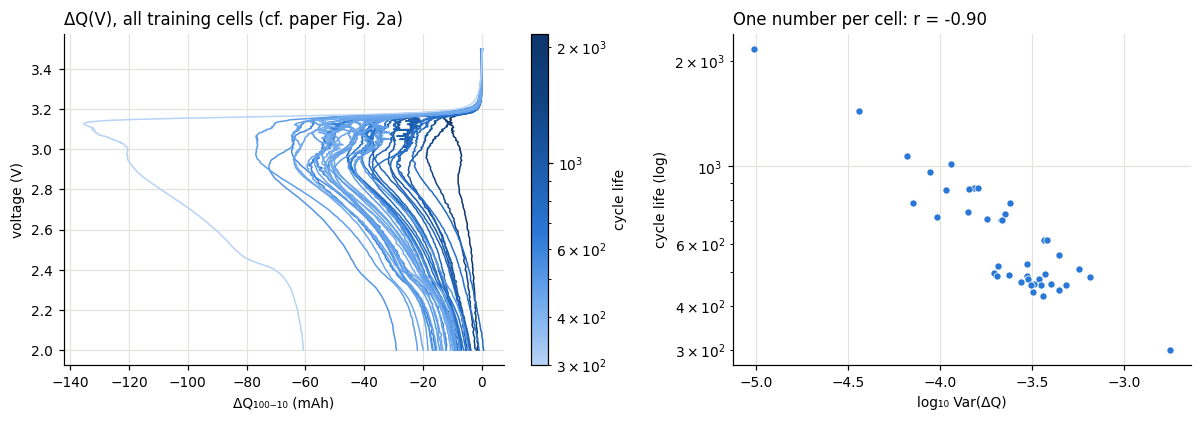

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
norm = LogNorm(train.cycle_life.min(), train.cycle_life.max())
for cid, row in train.sort_values("cycle_life", ascending=False).iterrows():
    axes[0].plot(1000 * delta_q(cells[cid]), VDLIN, color=BLUES(norm(row.cycle_life)), lw=1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=BLUES); fig.colorbar(sm, ax=axes[0], label="cycle life")
axes[0].set(xlabel="ΔQ₁₀₀₋₁₀ (mAh)", ylabel="voltage (V)", title="ΔQ(V), all training cells (cf. paper Fig. 2a)")
x = train.dq_log_var; y = np.log10(train.cycle_life)
axes[1].scatter(x, train.cycle_life, color=C1, s=22, edgecolor="white", lw=0.5)
axes[1].set_yscale("log")
axes[1].set(xlabel="log₁₀ Var(ΔQ)", ylabel="cycle life (log)", title=f"One number per cell: r = {np.corrcoef(x, y)[0,1]:.2f}")
for ax in axes: ax.title.set_ha("left"); ax.title.set_position((0, 1))
plt.tight_layout(); plt.show()

## 3 · The 20 candidate features

The paper's SI Table 1 lists 20 candidate features; each model uses a subset [paper]. All are computed from cycles ≤ 100.

| Group | Feature (`features.csv` column) | Meaning | Var. | Dis. | Full |
|---|---|---|:-:|:-:|:-:|
| ΔQ(V) | `dq_log_min` | log₁₀ \|min ΔQ\| | | ✓ | ✓ |
| | `dq_log_mean` | log₁₀ \|mean ΔQ\| | | | |
| | `dq_log_var` | log₁₀ Var(ΔQ) (sample variance) | ✓ | ✓ | ✓ |
| | `dq_log_skew` | log₁₀ \|skewness ΔQ\| | | ✓ | |
| | `dq_log_kurt` | log₁₀ \|kurtosis ΔQ\| | | ✓ | |
| | `dq_log_2v` | log₁₀ \|ΔQ at 2.0 V\| | | | |
| Capacity fade | `qd_slope_2_100`, `qd_icpt_2_100` | straight-line fit of QD vs cycle, cycles 2–100 | | | ✓ ✓ |
| | `qd_slope_91_100`, `qd_icpt_91_100` | same, cycles 91–100 | | | |
| | `qd_2` | QD at cycle 2 | | ✓ | ✓ |
| | `qd_max_minus_2` | max QD − QD(2) | | ✓ | |
| | `qd_100` | QD at cycle 100 | | | |
| Other | `chargetime_avg_2_6` | mean charge time, cycles 2–6 (≈ which policy) | | | ✓ |
| | `temp_max_2_100`, `temp_min_2_100` | max / min can temperature | | | |
| | `temp_integral_2_100` | ∫T dt summed over cycles 2–100 | | | ✓ |
| | `ir_2` | internal resistance at cycle 2 | | | |
| | `ir_min_2_100` | minimum IR, cycles 2–100 | | | ✓ |
| | `ir_100_minus_2` | IR(100) − IR(2) | | | ✓ |

**Implementation choices where SI Note 1 is ambiguous** [ours]: skewness/kurtosis as standard moment ratios
(the SI formula has a typo); capacity features use `QD_clean`; single-cycle values fall back to the nearest
finite cycle within ±3; the temperature integral skips sample gaps > 10 min (rule B10).

### One cell, by hand
The cell below recomputes the features of one cell with plain numpy, straight from the cleaned data, and
checks them against `features.csv` (which `src/features.py` produced). Change `CID` to try another cell.

In [5]:
import pickle
from config import PROC_DIR
extras = pickle.load(open(PROC_DIR / "extras.pkl", "rb"))   # per-cycle ∫T dt from raw traces (src/extras.py)

CID = "b2c10"
c = cells[CID]; s = c["summary"]; cyc = s["cycle"]
w = (cyc >= 2) & (cyc <= 100)                     # feature window: cycles 2..100

# --- ΔQ(V) features
dq = curve(c, "Qdlin", 100) - curve(c, "Qdlin", 10)
dev = dq - dq.mean()
m2, m3, m4 = (dev**2).mean(), (dev**3).mean(), (dev**4).mean()
# --- capacity-fade features (cleaned capacity, glitch cycles = NaN are skipped)
q = s["QD_clean"][w]; ok = np.isfinite(q)
slope, icpt = np.polyfit(cyc[w][ok], q[ok], 1)
q2 = s["QD_clean"][cyc == 2][0]
# --- other
e = extras[CID]; we = (e["cycle"] >= 2) & (e["cycle"] <= 100)
ir = s["IR"][w]

by_hand = {
    "dq_log_min":  np.log10(abs(dq.min())),
    "dq_log_var":  np.log10(np.var(dq, ddof=1)),
    "dq_log_skew": np.log10(abs(m3 / m2**1.5)),
    "dq_log_kurt": np.log10(abs(m4 / m2**2)),
    "qd_slope_2_100": slope, "qd_icpt_2_100": icpt,
    "qd_2": q2, "qd_max_minus_2": np.nanmax(q) - q2,
    "chargetime_avg_2_6": np.nanmean(s["chargetime"][(cyc >= 2) & (cyc <= 6)]),
    "temp_integral_2_100": e["T_int"][we].sum(),
    "ir_min_2_100": np.nanmin(ir),
    "ir_100_minus_2": s["IR"][cyc == 100][0] - s["IR"][cyc == 2][0],
}
units = {"qd_slope_2_100": "Ah/cycle", "qd_icpt_2_100": "Ah", "qd_2": "Ah", "qd_max_minus_2": "Ah",
         "chargetime_avg_2_6": "min", "temp_integral_2_100": "°C·min", "ir_min_2_100": "Ω", "ir_100_minus_2": "Ω"}
chk = pd.DataFrame({"by hand": by_hand, "features.csv": df.loc[CID, list(by_hand)]})
chk["unit"] = [units.get(k, "log10") for k in chk.index]
chk["match"] = np.isclose(chk["by hand"].astype(float), chk["features.csv"].astype(float), rtol=1e-6)
print(f"{CID}: policy {c['policy']}, life {c['cycle_life']:.0f}, split {df.loc[CID,'split']}")
chk

b2c10: policy 3.6C(9%)-5C, life 561, split primary_test


,by hand,features.csv,unit,match
dq_log_min,-1.315854,-1.315854,log10,True
dq_log_var,-3.625879,-3.625879,log10,True
dq_log_skew,-0.781129,-0.781129,log10,True
dq_log_kurt,0.280798,0.280798,log10,True
qd_slope_2_100,-0.000060,-0.00006,Ah/cycle,True
qd_icpt_2_100,1.074593,1.074593,Ah,True
qd_2,1.069052,1.069052,Ah,True
qd_max_minus_2,0.004890,0.00489,Ah,True
chargetime_avg_2_6,10.114951,10.114951,min,True
temp_integral_2_100,196541.223889,196541.223889,°C·min,True


In [6]:
# The whole feature table (first rows) and the range of every feature over the 124 paper cells
display(df[["split", "batch", "policy", "cycle_life"] + FEATURE_SETS["full"]].head(6))
paper[ALL_CANDIDATES].describe().T[["mean", "std", "min", "max"]].round(4)

,split,batch,policy,cycle_life,dq_log_min,dq_log_var,qd_slope_2_100,qd_icpt_2_100,qd_2,chargetime_avg_2_6,temp_integral_2_100,ir_min_2_100,ir_100_minus_2
cell,,,,,,,,,,,,,
b1c1,train,b1,3.6C(80%)-3.6C,2160.0,-1.958456,-5.013525,0.000006,1.080965,1.075301,13.409150,167926.610236,0.016764,-0.000042
b1c3,train,b1,4C(80%)-4C,1434.0,-1.722149,-4.442179,0.000017,1.084075,1.079723,12.025140,157007.461679,0.016098,0.000039
b1c5,train,b1,4.4C(80%)-4.4C,1074.0,-1.598966,-4.178444,0.000011,1.079755,1.076127,10.967850,158743.094660,0.015923,-0.000112
b1c7,train,b1,4.8C(80%)-4.8C,870.0,-1.417558,-3.813052,-0.000006,1.097254,1.093864,10.025082,161065.490687,0.016083,-0.000038
b1c11,train,b1,5.4C(50%)-3C,788.0,-1.625408,-4.146462,0.000022,1.058972,1.053779,11.668876,169734.782687,0.015963,-0.000304
b1c15,train,b1,5.4C(60%)-3C,719.0,-1.538433,-4.017515,0.000029,1.066175,1.061124,10.797706,168929.234838,0.016543,-0.000253


,mean,std,min,max
dq_log_min,-1.4350,0.2046,-2.0726,-0.8600
dq_log_mean,-1.7850,0.2394,-2.5416,-1.1097
dq_log_var,-3.8360,0.4126,-5.0144,-2.7265
dq_log_skew,-0.7946,0.4116,-2.3379,0.0335
dq_log_kurt,0.2555,0.0396,0.2076,0.5249
dq_log_2v,-2.1957,0.3711,-3.2352,-1.0420
qd_slope_2_100,-0.0000,0.0001,-0.0011,0.0000
qd_icpt_2_100,1.0751,0.0096,1.0494,1.0984
qd_slope_91_100,-0.0001,0.0001,-0.0014,0.0000
qd_icpt_91_100,1.0793,0.0103,1.0500,1.1092


## 4 · Which features relate to life? (training cells only)

Correlation of each feature with log₁₀(life) over the 41 training cells. ΔQ features dominate, as in the paper's Fig. 2.
Only the training cells are used here, as the models also only see training cells.

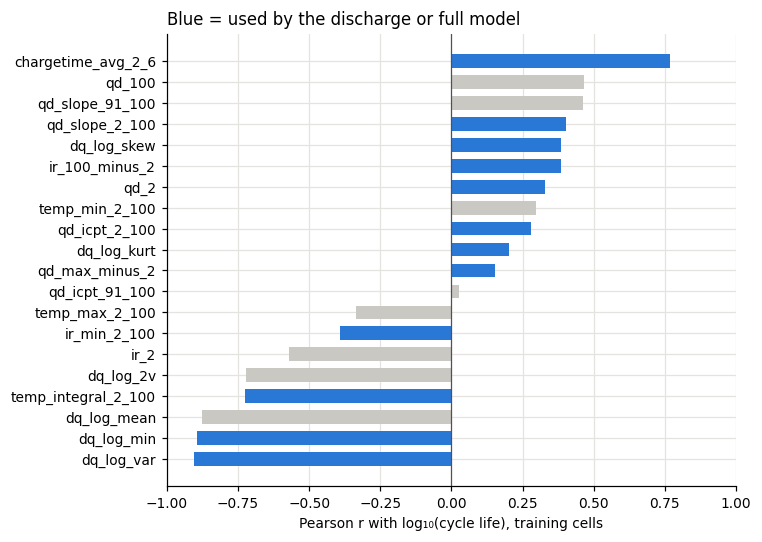

In [7]:
y = np.log10(train.cycle_life)
r = train[ALL_CANDIDATES].apply(lambda col: np.corrcoef(col.fillna(col.median()), y)[0, 1]).sort_values()
used = set(FEATURE_SETS["discharge"]) | set(FEATURE_SETS["full"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(r.index, r.values, color=[C1 if k in used else "#c9c8c3" for k in r.index], height=0.65)
ax.axvline(0, color=INK2, lw=0.8)
ax.set(xlabel="Pearson r with log₁₀(cycle life), training cells", xlim=(-1, 1))
ax.set_title("Blue = used by the discharge or full model", loc="left")
plt.tight_layout(); plt.show()

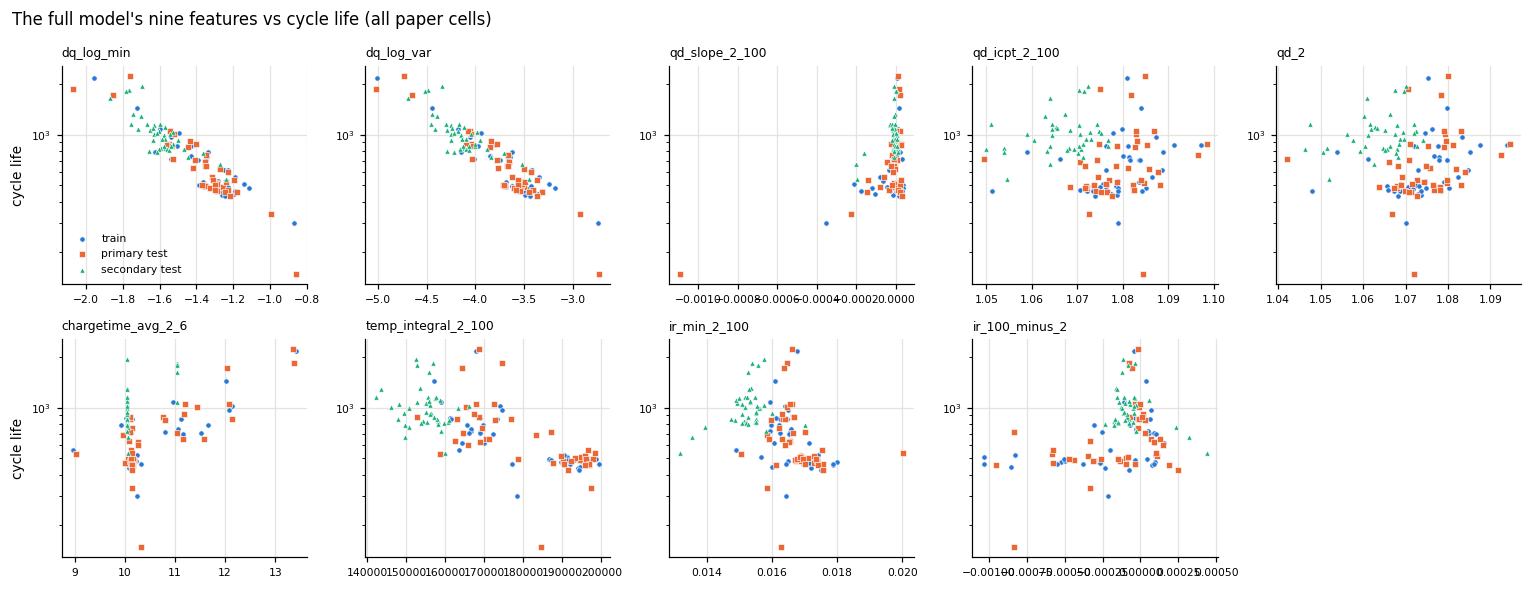

In [8]:
feats = FEATURE_SETS["full"]
fig, axes = plt.subplots(2, 5, figsize=(14, 5.4)); axes = axes.ravel()
for ax, f in zip(axes, feats):
    for split, (lab, col, mk) in SPLIT_STYLE.items():
        d = paper[paper.split == split]
        ax.scatter(d[f], d.cycle_life, color=col, marker=mk, s=12, edgecolor="white", lw=0.4, label=lab)
    ax.set_yscale("log"); ax.set_title(f, fontsize=8, loc="left"); ax.tick_params(labelsize=7)
axes[0].set_ylabel("cycle life"); axes[5].set_ylabel("cycle life")
axes[-1].axis("off"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("The full model's nine features vs cycle life (all paper cells)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

Things to notice [data]:
* `dq_log_var` and `dq_log_min` give a clean, almost straight trend for train **and** both test sets.
* `qd_2`: the **secondary** cells (green) sit at lower initial capacity than train — the paper explains
  this by ~1 extra year of calendar ageing before testing [paper]. A model leaning on capacity features is biased there.
* `chargetime_avg_2_6` is essentially the charging policy: within b1 (charge times 9.0–13.4 min) a longer charge
  (lower current) means a longer life; all b2 policies take ~10.2 min.
* `temp_integral_2_100` (r = −0.72 overall) is mostly a **batch** effect, not heating: b2 cycles contain two 5-min rests,
  so they last longer and accumulate a larger ∫T dt, and b2 cells also live shorter. Within one batch the correlation
  is weak (run the next cell).

In [9]:
# temperature integral and charge time: overall vs within each batch (training cells)
for b, d in train.groupby("batch"):
    yy = np.log10(d.cycle_life)
    print(f"{b}: n={len(d)}  mean life {d.cycle_life.mean():4.0f}  mean ∫T dt {d.temp_integral_2_100.mean():8.0f}"
          f"  r(∫T dt, log life) {np.corrcoef(d.temp_integral_2_100, yy)[0,1]:+.2f}"
          f"  r(charge time, log life) {np.corrcoef(d.chargetime_avg_2_6, yy)[0,1]:+.2f}")

b1: n=20  mean life  889  mean ∫T dt   166947  r(∫T dt, log life) -0.14  r(charge time, log life) +0.77
b2: n=21  mean life  469  mean ∫T dt   191510  r(∫T dt, log life) +0.45  r(charge time, log life) -0.16


## 5 · The three models

All three predict **log₁₀(cycle life)**; predictions are converted back with 10^ŷ before scoring.
Every model is a scikit-learn pipeline:

```
SimpleImputer(median)  →  StandardScaler (z-score)  →  regressor
```
* **Imputer** [ours]: fills a missing value with the *training* median. Only `b1c18`'s IR features are missing (§8).
* **Scaler**: puts features on the same scale so the penalty treats them fairly and coefficients are comparable.
* **Regressor**:
  * *variance model* — ordinary least squares on one feature, no tuning [paper];
  * *discharge* and *full* — **elastic net** [paper]: least squares + penalty α·(ℓ₁·|w| + (1−ℓ₁)/2·w²).
    The ℓ₁ part can set weights to exactly 0 (feature selection); the ℓ₂ part handles correlated features.
    With only 41 cells, this penalty prevents overfitting.
* **Tuning:** α (100 values) and the ℓ₁ ratio (8 values) are chosen by **4-fold cross-validation repeated 10 times**
  on the training cells only [paper: 4-fold CV + Monte Carlo sampling; ours: `RepeatedKFold`].
* The **full** model leaves out the 4 cells whose temperature probe lost contact (rule B6) [paper].

### 5.1 Variance model: a straight line

fitted:  log10(life) = 1.346 -0.396 * log10 Var(ΔQ)


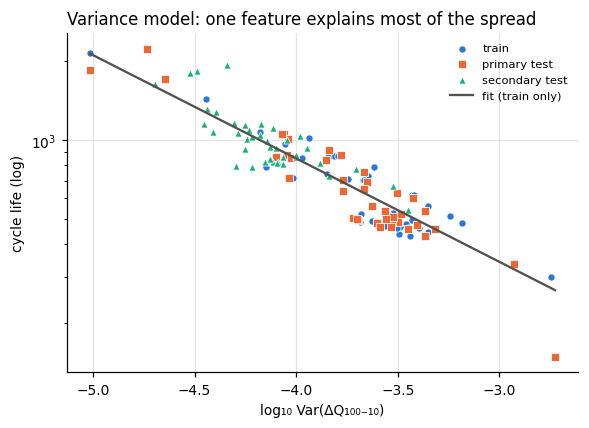

In [10]:
m_var, res_var, info_var = fit_one(df, "variance")
# undo the z-scoring to show the line in raw units: log10(life) = a + b * log10 Var(ΔQ)
imp, sc, ols = m_var
b = ols.coef_[0] / sc.scale_[0]; a = ols.intercept_ - b * sc.mean_[0]
print(f"fitted:  log10(life) = {a:.3f} {b:+.3f} * log10 Var(ΔQ)")

fig, ax = plt.subplots(figsize=(6, 4))
for split, (lab, col, mk) in SPLIT_STYLE.items():
    d = paper[paper.split == split]
    ax.scatter(d.dq_log_var, d.cycle_life, color=col, marker=mk, s=22, edgecolor="white", lw=0.5, label=lab)
xs = np.linspace(paper.dq_log_var.min(), paper.dq_log_var.max(), 50)
ax.plot(xs, 10 ** (a + b * xs), color=INK2, lw=1.5, label="fit (train only)")
ax.set_yscale("log"); ax.set(xlabel="log₁₀ Var(ΔQ₁₀₀₋₁₀)", ylabel="cycle life (log)")
ax.set_title("Variance model: one feature explains most of the spread", loc="left")
ax.legend(fontsize=7.5); plt.show()

### 5.2 Discharge and full models: elastic net

The plot shows the cross-validation error for every (α, ℓ₁ ratio) tried; the dot is the chosen one.
Larger α = stronger penalty = simpler model. Too small → overfits; too large → underfits.

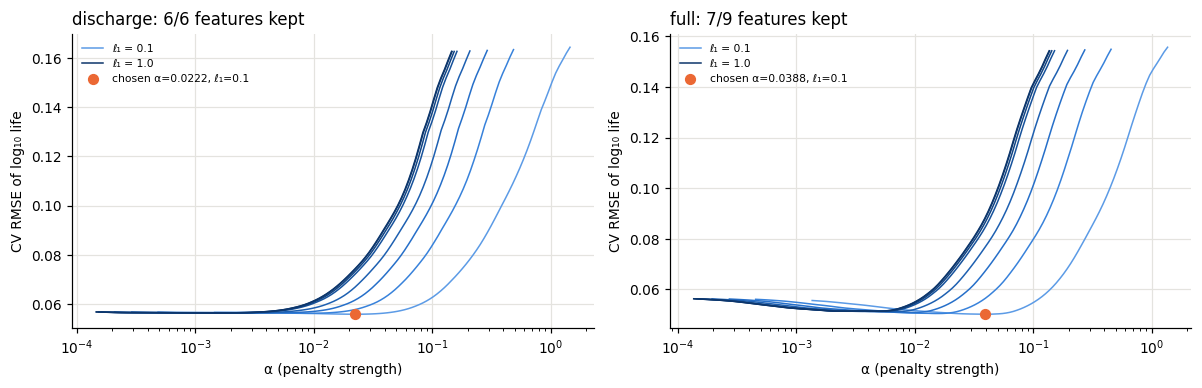

In [11]:
fits = {name: fit_one(df, name) for name in ("variance", "discharge", "full")}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, name in zip(axes, ("discharge", "full")):
    en = fits[name][0][-1]
    mse = en.mse_path_.mean(axis=-1)          # (n_l1, n_alpha): mean CV error
    for i, l1 in enumerate(en.l1_ratio):
        ax.plot(en.alphas_[i], np.sqrt(mse[i]), lw=1, color=BLUES(0.25 + 0.75 * i / (len(en.l1_ratio) - 1)),
                label=f"ℓ₁ = {l1}" if i in (0, len(en.l1_ratio) - 1) else None)
    ax.scatter([en.alpha_], [np.sqrt(mse.min())], color=C2, zorder=5, s=40, label=f"chosen α={en.alpha_:.3g}, ℓ₁={en.l1_ratio_}")
    ax.set_xscale("log"); ax.set(xlabel="α (penalty strength)", ylabel="CV RMSE of log₁₀ life")
    ax.set_title(f"{name}: {fits[name][2]['n_selected']}/{len(FEATURE_SETS[name])} features kept", loc="left")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

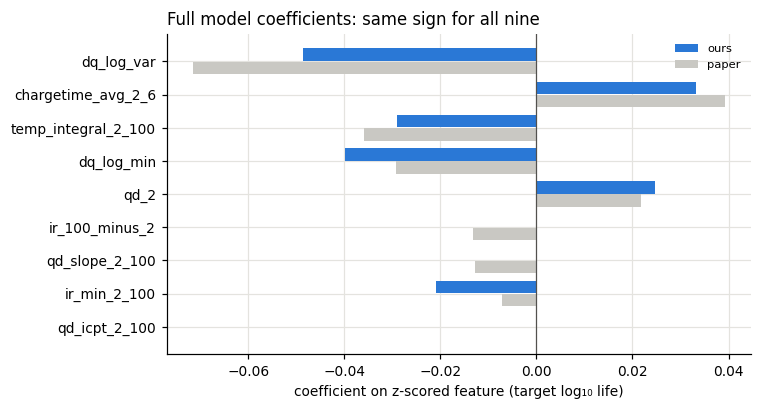

,ours,paper (SI Fig. 5),same sign (or zeroed)
qd_icpt_2_100,0.0000,0.0000,True
ir_min_2_100,-0.0208,-0.0071,True
qd_slope_2_100,-0.0000,-0.0127,True
ir_100_minus_2,-0.0002,-0.0132,True
qd_2,0.0246,0.0218,True
dq_log_min,-0.0398,-0.0293,True
temp_integral_2_100,-0.0291,-0.0359,True
chargetime_avg_2_6,0.0333,0.0392,True
dq_log_var,-0.0486,-0.0714,True


In [12]:
coef = pd.DataFrame({"ours": fits["full"][2]["coef"], "paper (SI Fig. 5)": PAPER_FULL_COEF})
coef = coef.reindex(coef["paper (SI Fig. 5)"].abs().sort_values().index)
fig, ax = plt.subplots(figsize=(7, 3.8))
yy = np.arange(len(coef))
ax.barh(yy + 0.2, coef["ours"], height=0.38, color=C1, label="ours")
ax.barh(yy - 0.2, coef["paper (SI Fig. 5)"], height=0.38, color="#c9c8c3", label="paper")
ax.set_yticks(yy); ax.set_yticklabels(coef.index); ax.axvline(0, color=INK2, lw=0.8)
ax.set(xlabel="coefficient on z-scored feature (target log₁₀ life)")
ax.set_title("Full model coefficients: same sign for all nine", loc="left"); ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()
coef["same sign (or zeroed)"] = (np.sign(coef.ours) == np.sign(coef["paper (SI Fig. 5)"])) | (coef.ours.abs() < 1e-3)
coef.round(4)

How to read a coefficient: +0.03 means one standard deviation more of that feature → log₁₀ life +0.03 → life ×1.07.
The negative ΔQ-variance weight says: bigger change in the discharge curve → shorter life.

## 6 · Results vs the paper's Table 1

Metrics are computed on **cycles** (not on log): RMSE in cycles and mean absolute percentage error [paper].
"Primary excl." leaves out the anomalous cell `b2c1` [paper].

In [13]:
KEYS = ("train", "primary", "primary_excl", "secondary")
base = baselines(df)
rows = {"constant": base["constant"], "policy mean (ours)": base["policy_mean"]}
rows.update({n: fits[n][1] for n in ("variance", "discharge", "full")})
tab = {}
for n, sc in rows.items():
    pn = PAPER.get(n.split(" ")[0] if n != "policy mean (ours)" else "", {})
    tab[n] = {k: f"{sc[k]['rmse']:.0f} / {sc[k]['mape']:.1f}%" + (f"   ({pn[k][0]} / {pn[k][1]}%)" if k in pn else "")
              for k in KEYS}
print("RMSE (cycles) / mean % error — ours   (paper)")
pd.DataFrame(tab).T.rename(columns={"primary_excl": "primary excl. b2c1"})

RMSE (cycles) / mean % error — ours   (paper)


,train,primary,primary excl. b2c1,secondary
constant,327 / 29.6% (327 / 29.6%),401 / 35.0% (401 / 34.9%),399 / 28.2% (399 / 28.2%),511 / 36.1% (511 / 36.1%)
policy mean (ours),46 / 1.6%,173 / 27.3%,159 / 20.3%,509 / 36.0%
variance,104 / 14.1% (103 / 14.1%),138 / 14.7% (138 / 14.7%),138 / 13.2% (138 / 13.2%),196 / 11.4% (196 / 11.4%)
discharge,69 / 9.2% (76 / 9.8%),90 / 12.6% (91 / 13.0%),85 / 9.4% (86 / 10.1%),167 / 9.9% (173 / 8.6%)
full,67 / 6.8% (51 / 5.6%),125 / 11.0% (118 / 14.1%),122 / 8.0% (100 / 7.5%),220 / 11.2% (214 / 10.7%)


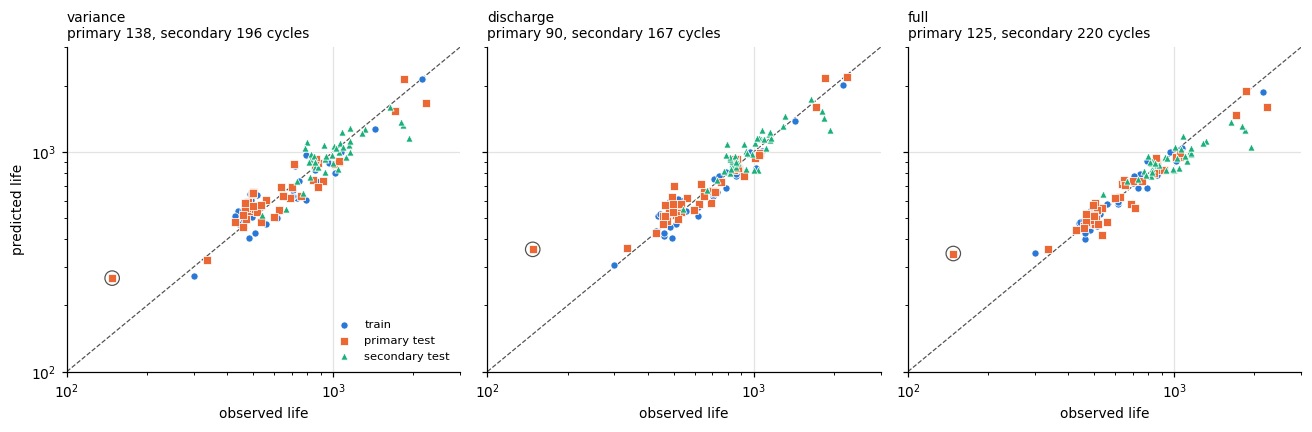

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
lim = (100, 3000)
preds = {}
for ax, name in zip(axes, ("variance", "discharge", "full")):
    model = fits[name][0]; cols = FEATURE_SETS[name]
    d = paper[~paper.temp_suspect] if name == "full" else paper
    d = d.assign(pred=10 ** model.predict(d[cols].values)); preds[name] = d
    for split, (lab, col, mk) in SPLIT_STYLE.items():
        s = d[d.split == split]
        ax.scatter(s.cycle_life, s.pred, color=col, marker=mk, s=22, edgecolor="white", lw=0.5, label=lab, zorder=3)
    an = d[d.anomalous]
    ax.scatter(an.cycle_life, an.pred, s=90, facecolor="none", edgecolor=INK2, lw=0.8, zorder=4)
    ax.plot(lim, lim, color=INK2, lw=0.8, ls="--")
    sc = fits[name][1]
    ax.set_title(f"{name}\nprimary {sc['primary']['rmse']:.0f}, secondary {sc['secondary']['rmse']:.0f} cycles", loc="left", fontsize=9)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("observed life")
axes[0].set_ylabel("predicted life"); axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.show()

**Reading the result**
* **Variance model: matches the paper to within one cycle on every split.** It has no tuning, so this tests only the
  data and the feature — confirming that our ΔQ, labels and splits are identical to the paper's.
* **Discharge model:** within 1–9% of the paper's RMSE.
* **Full model:** close on the test sets (125 vs 118, 220 vs 214); see §7 for the primary gap.
* **Same ranking as the paper on every split**, including the paper's surprising result that the full model is
  *worse* than the discharge model on the secondary set (capacity features biased by calendar ageing, see §4).
* Remaining small differences are expected: the paper uses MATLAB, its own random CV sampling, and a spline fit of the
  discharge curves; our seed-to-seed spread is of the same size (§9).

## 7 · Where the errors come from

In [15]:
d = preds["full"].copy()
d["err"] = d.pred - d.cycle_life
prim = d[d.split == "primary_test"].copy()
prim["share of squared error"] = prim.err**2 / (prim.err**2).sum()
print("Full model, primary test: the 5 cells with the largest errors")
display(prim.sort_values("share of squared error", ascending=False)
        [["policy", "cycle_life", "pred", "err", "share of squared error"]].head(5).round(2))
wo = prim.drop(index="b1c2")
print(f"primary RMSE {np.sqrt((prim.err**2).mean()):.0f} cycles; without b1c2 (longest-lived cell, 2237): {np.sqrt((wo.err**2).mean()):.0f}")
ex = prim.drop(index="b2c1")
print(f"primary excl. b2c1: RMSE {np.sqrt((ex.err**2).mean()):.0f}; b1c2's share {ex.err['b1c2']**2 / (ex.err**2).sum():.0%};"
      f" without b1c2 too: {np.sqrt((ex.drop(index='b1c2').err**2).mean()):.0f}")

Full model, primary test: the 5 cells with the largest errors


,policy,cycle_life,pred,err,share of squared error
cell,,,,,
b1c2,3.6C(80%)-3.6C,2237.0,1593.93,-643.07,0.63
b1c4,4C(80%)-4C,1709.0,1471.18,-237.82,0.09
b2c1,2C(10%)-6C,148.0,344.73,196.73,0.06
b2c47,6C(60%)-3C,713.0,555.77,-157.23,0.04
b2c36,5.6C(25%)-4.5C,535.0,417.30,-117.70,0.02


primary RMSE 125 cycles; without b1c2 (longest-lived cell, 2237): 76
primary excl. b2c1: RMSE 122; b1c2's share 67%; without b1c2 too: 71


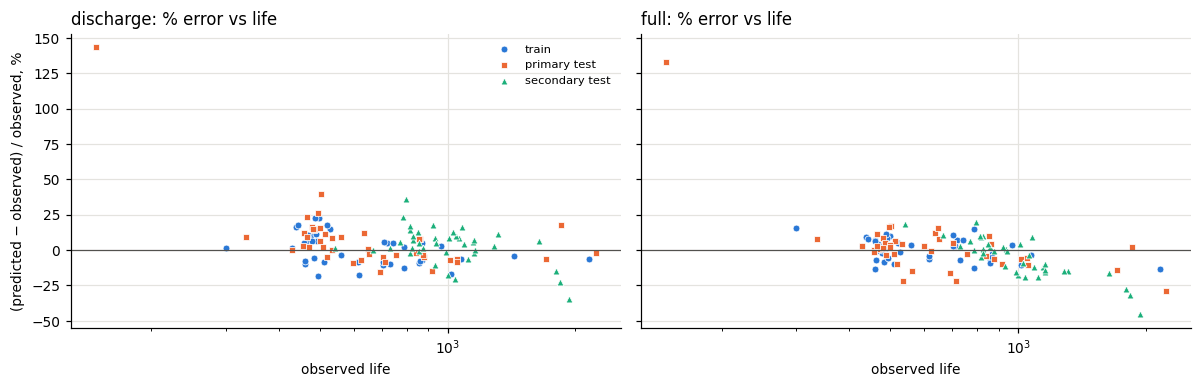

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, name in zip(axes, ("discharge", "full")):
    d = preds[name]
    for split, (lab, col, mk) in SPLIT_STYLE.items():
        s = d[d.split == split]
        ax.scatter(s.cycle_life, 100 * (s.pred - s.cycle_life) / s.cycle_life, color=col, marker=mk, s=20,
                   edgecolor="white", lw=0.5, label=lab)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xscale("log")
    ax.set(xlabel="observed life", title=f"{name}: % error vs life"); ax.title.set_ha("left"); ax.title.set_position((0, 1))
axes[0].set_ylabel("(predicted − observed) / observed, %"); axes[0].legend(fontsize=7.5)
plt.tight_layout(); plt.show()

[data] Two patterns:
* **The longest-lived cells are under-predicted** (points below 0 on the right) — few training cells live > 1500 cycles,
  so the model shrinks towards the middle. `b1c2` alone is 63% of the full model's primary squared error
  (67% once `b2c1` is excluded; that RMSE drops from 122 to 71 without it).
* **`b2c1`** (148 cycles) is predicted far too long by every model: it failed early for a reason not visible in
  cycles ≤ 100 [paper calls it anomalous].

## 8 · Case study: `b1c18` — the reproduction found a data fault

Our **first** full-model fit predicted **0 cycles** for `b1c18` (primary RMSE 162 instead of ~118).
The paper's numbers acted as a check: something in our data had to be wrong. The cause, in cycles 2–53 of this cell:
1. the **IR logger was stuck**, repeating 19.886 mΩ for 52 cycles (no other cell repeats a value more than twice);
2. every cycle record has a **corrupt time stamp** that jumps by ~4000 min, which inflates ∫T dt.

Fixes (Phase 1 rules, added in Phase 2): **B9** stuck IR → NaN (then training-median imputation),
**B10** sample gaps > 10 min left out of ∫T dt.

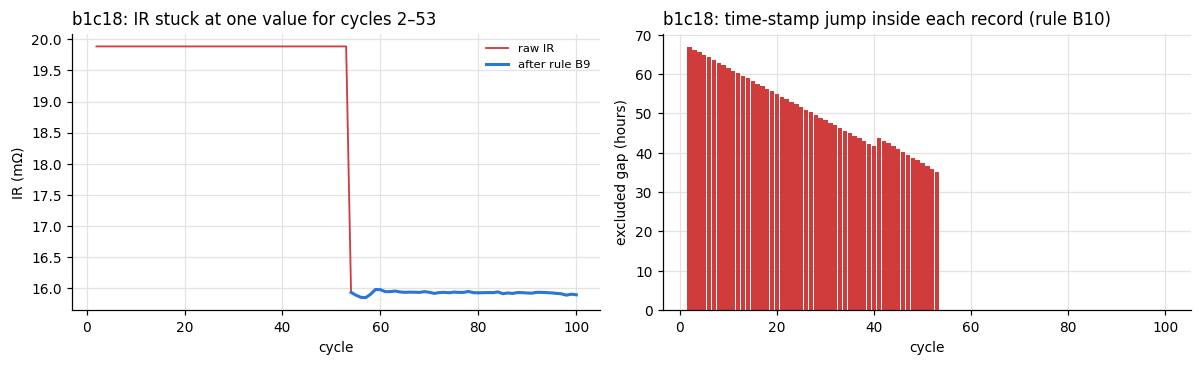

In [17]:
raw = pickle.load(open(PROC_DIR / "b1_raw.pkl", "rb"))["cells"]["b1c18"]["summary"]
cl = cells["b1c18"]["summary"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
m = (raw["cycle"] >= 2) & (raw["cycle"] <= 100)
ir_raw = np.where(raw["IR"] > 0, raw["IR"], np.nan)
axes[0].plot(raw["cycle"][m], 1000 * ir_raw[m], color=BAD, lw=1.2, label="raw IR")
mc = (cl["cycle"] >= 2) & (cl["cycle"] <= 100)
axes[0].plot(cl["cycle"][mc], 1000 * cl["IR"][mc], color=C1, lw=2, label="after rule B9")
axes[0].set(xlabel="cycle", ylabel="IR (mΩ)", title="b1c18: IR stuck at one value for cycles 2–53")
axes[0].legend(fontsize=7.5)

e = extras["b1c18"]; mm = (e["cycle"] >= 2) & (e["cycle"] <= 100)
axes[1].bar(e["cycle"][mm], e["t_gap"][mm] / 60, color=BAD, width=0.9)
axes[1].set(xlabel="cycle", ylabel="excluded gap (hours)", title="b1c18: time-stamp jump inside each record (rule B10)")
for ax in axes: ax.title.set_ha("left"); ax.title.set_position((0, 1))
plt.tight_layout(); plt.show()

In [18]:
# What the full model predicts for b1c18 if we undo the two fixes.
# 1) IR features from the raw (stuck) IR values
bad = df.loc[["b1c18"]].copy()
ir_at = lambda n: ir_raw[raw["cycle"] == n][0]
bad["ir_min_2_100"] = np.nanmin(ir_raw[m])
bad["ir_100_minus_2"] = ir_at(100) - ir_at(2)
# 2) ∫T dt straight from the raw traces, WITHOUT skipping the time-stamp gaps (reads the .mat file, ~2 s)
import h5py
from config import RAW_DIR, BATCHES
with h5py.File(RAW_DIR / BATCHES["b1"], "r") as f:
    g = f[f["batch"]["cycles"][cells["b1c18"]["index_in_batch"], 0]]
    tot = 0.0
    for n in range(2, 101):                        # record n-1 holds cycle n
        t = np.asarray(f[g["t"][n - 1, 0]]).ravel(); T = np.asarray(f[g["T"][n - 1, 0]]).ravel()
        ok = np.isfinite(t) & np.isfinite(T)
        tot += np.trapz(T[ok], t[ok])
bad["temp_integral_2_100"] = tot

model_full, cols = fits["full"][0], FEATURE_SETS["full"]
z = lambda row: (row[cols].values - train[~train.temp_suspect][cols].mean().values) / train[~train.temp_suspect][cols].std().values
out = pd.DataFrame({
    "unfixed": {"temp_integral (z)": z(bad.iloc[0])[cols.index("temp_integral_2_100")],
                "IR(100)-IR(2) (z)": z(bad.iloc[0])[cols.index("ir_100_minus_2")],
                "predicted life": 10 ** model_full.predict(bad[cols].values)[0]},
    "fixed (B9 + B10)": {"temp_integral (z)": z(df.loc["b1c18"])[cols.index("temp_integral_2_100")],
                         "IR(100)-IR(2) (z)": np.nan,
                         "predicted life": 10 ** model_full.predict(df.loc[["b1c18"], cols].values)[0]},
}).round(1)
print(f"b1c18 observed life: {df.loc['b1c18', 'cycle_life']:.0f} cycles  (z = standard deviations from the training mean)")
out

b1c18 observed life: 691 cycles  (z = standard deviations from the training mean)


,unfixed,fixed (B9 + B10)
temp_integral (z),372.3,0.2
IR(100)-IR(2) (z),-11.9,NaN
predicted life,0.0,578.2


With the fault, the temperature integral sits hundreds of standard deviations from the training data, and the
linear model extrapolates to a life of ~0 cycles. After the fixes the prediction is sensible.

**Lesson:** reproduce before you innovate. The paper's numbers were a test that our Phase 1 cleaning had not yet passed.

## 9 · Stability over cross-validation seeds

The elastic net's α and ℓ₁ are chosen by random CV folds. Refit with 10 different seeds: how much do the test errors move?

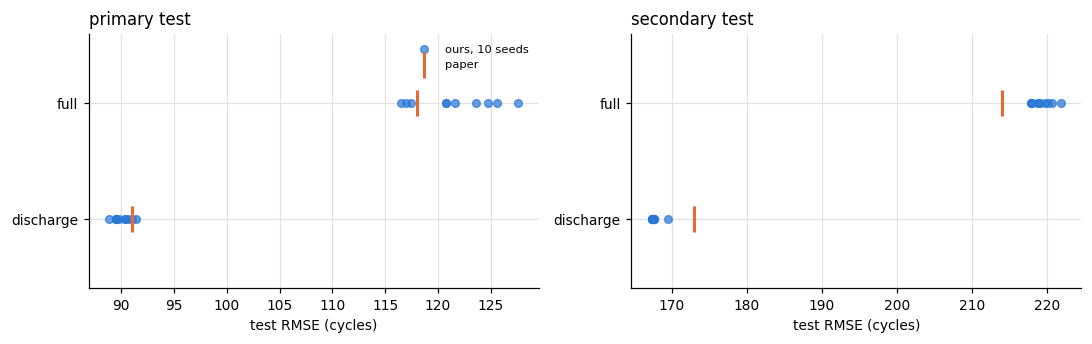

min    max
model     split                  
discharge primary     89.0   91.0
          secondary  167.0  170.0
full      primary    117.0  128.0
          secondary  218.0  222.0

In [19]:
rows = []
for seed in range(10):
    for name in ("discharge", "full"):
        sc = fit_one(df, name, seed=seed)[1]
        rows += [{"model": name, "seed": seed, "split": k, "rmse": sc[k]["rmse"]} for k in ("primary", "secondary")]
st = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, split in zip(axes, ("primary", "secondary")):
    for i, name in enumerate(("discharge", "full")):
        v = st[(st.model == name) & (st.split == split)].rmse
        ax.scatter(v, [i] * len(v), color=C1, s=25, alpha=0.7, label="ours, 10 seeds" if i == 0 else None)
        ax.scatter([PAPER[name][split][0]], [i], marker="|", s=300, color=C2, lw=2, label="paper" if i == 0 else None)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["discharge", "full"]); ax.set_ylim(-0.6, 1.6)
    ax.set(xlabel="test RMSE (cycles)", title=f"{split} test"); ax.title.set_ha("left"); ax.title.set_position((0, 1))
axes[0].legend(fontsize=7.5)
plt.tight_layout(); plt.show()
st.groupby(["model", "split"]).rmse.agg(["min", "max"]).round(0)

## 10 · Explore any cell

`explain_cell("b1c2")` shows the cell's features (as z-scores vs the training cells) and what each model predicts.

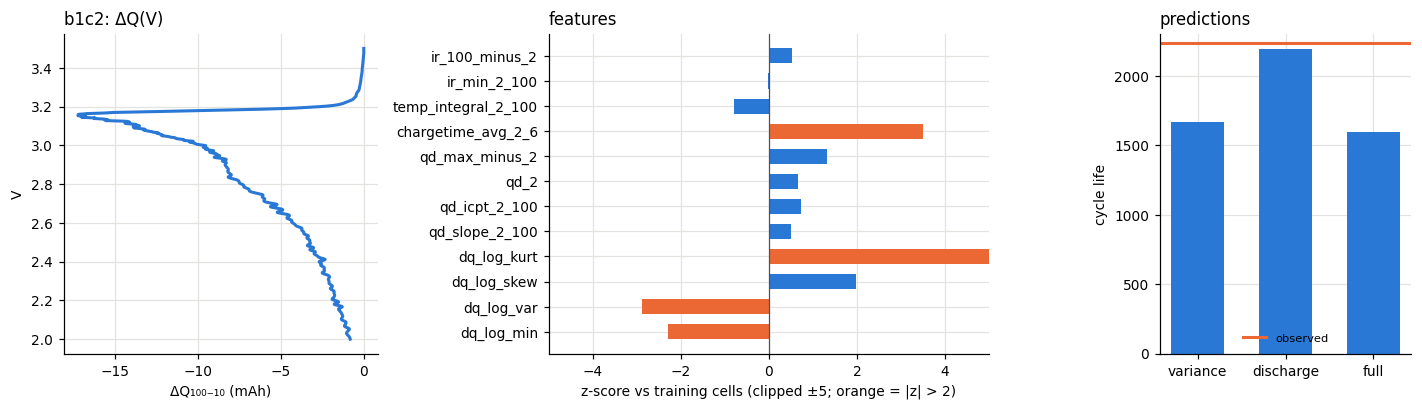

b1c2 | split primary_test | policy 3.6C(80%)-3.6C | observed life 2237 | variance 1664 | discharge 2192 | full 1594


In [20]:
def explain_cell(cid):
    row = df.loc[cid]
    zs = ((df.loc[cid, ALL_CANDIDATES] - train[ALL_CANDIDATES].mean()) / train[ALL_CANDIDATES].std()).astype(float)
    preds_c = {}
    for name in ("variance", "discharge", "full"):
        if name == "full" and row.temp_suspect:
            preds_c[name] = np.nan; continue
        preds_c[name] = 10 ** fits[name][0].predict(df.loc[[cid], FEATURE_SETS[name]].values)[0]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4, 0.8]})
    c = cells[cid]
    axes[0].plot(1000 * delta_q(c), VDLIN, color=C1, lw=2)
    axes[0].set(xlabel="ΔQ₁₀₀₋₁₀ (mAh)", ylabel="V", title=f"{cid}: ΔQ(V)")
    used = set(FEATURE_SETS["discharge"]) | set(FEATURE_SETS["full"])
    zz = zs[[f for f in ALL_CANDIDATES if f in used]]
    axes[1].barh(zz.index, zz.values.clip(-5, 5), color=[C2 if abs(v) > 2 else C1 for v in zz.values], height=0.6)
    axes[1].axvline(0, color=INK2, lw=0.8); axes[1].set_xlim(-5, 5)
    axes[1].set(xlabel="z-score vs training cells (clipped ±5; orange = |z| > 2)", title="features")
    names = list(preds_c); vals = [preds_c[n] for n in names]
    axes[2].bar(names, vals, color=C1, width=0.6); axes[2].axhline(row.cycle_life, color=C2, lw=2, label="observed")
    axes[2].set(ylabel="cycle life", title="predictions"); axes[2].legend(fontsize=7.5)
    for ax in axes: ax.title.set_ha("left"); ax.title.set_position((0, 1))
    plt.tight_layout(); plt.show()
    print(f"{cid} | split {row.split} | policy {row.policy} | observed life {row.cycle_life:.0f}"
          + "".join(f" | {n} {v:.0f}" for n, v in preds_c.items() if np.isfinite(v)))

explain_cell("b1c2")      # longest-lived cell, under-predicted

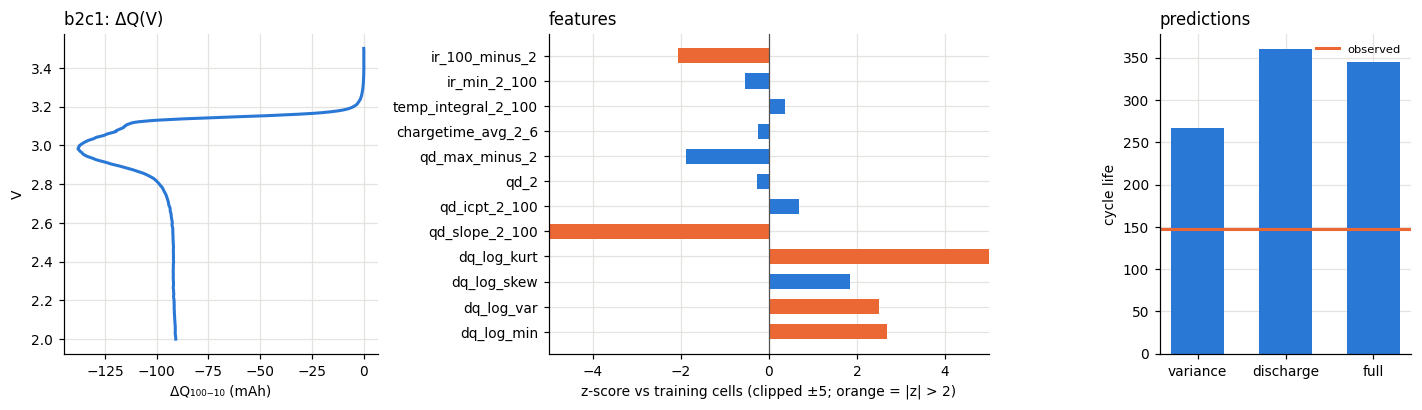

b2c1 | split primary_test | policy 2C(10%)-6C | observed life 148 | variance 266 | discharge 360 | full 345


In [21]:
explain_cell("b2c1")      # the anomalous early failure

In [22]:
try:
    import ipywidgets as W
    W.interact(explain_cell, cid=W.Dropdown(options=sorted(paper.index, key=lambda c: (c[:2], int(c.split("c")[1]))),
                                            value="b3c10", description="cell"))
except ImportError:
    print("ipywidgets not installed: call explain_cell('<cell id>') directly")

interactive(children=(Dropdown(description='cell', index=93, options=('b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4', …

## 11 · Summary — answer to RQ1

**Can the paper's results be reproduced from the public data? Yes.**

| | Result |
|---|---|
| Variance model | identical to the paper (±1 cycle) on every split → data, ΔQ feature, labels and split are right |
| Discharge model | within 1–9% of the paper's RMSE |
| Full model | close on test (125 vs 118, 220 vs 214); same coefficient signs |
| Model ranking | same as the paper on every split |
| Constant baseline | identical to SI Table 3 (it is the *geometric* mean of training life) |
| Bonus | found and fixed a data fault (`b1c18`) that Phase 1 had missed |

What this gives Phase 3+: a verified feature pipeline (`features.csv`), evaluation code, and baseline numbers that any
new model or new physics feature (F4) has to beat.